In [44]:
pip install pandas xlrd openpyxl keras scikit-learn tensorflow

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import keras
from keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, f1_score, precision_recall_curve,
                             average_precision_score)
from sklearn.utils.class_weight import compute_class_weight
SEED = 42
np.random.seed(SEED)
pd.set_option("display.float_format", "{:.2f}".format)

df = pd.read_csv("dados/healthcare-dataset-stroke-data.csv")

# Descrição do Problema e Dataset

O acidente vascular cerebral (AVC) é uma das principais causas de morte e incapacidade no mundo. Identificar precocemente pacientes com maior risco permite priorizar acompanhamento e ações preventivas. Neste trabalho, uma rede neural densa (MLP) construída em Keras é treinada para estimar, a partir de dados demográficos, clínicos e de hábitos de vida, se um paciente teve AVC.

Trata-se de uma classificação binária supervisionada. A variável-alvo é stroke, que vale 1 se o paciente teve AVC e 0 caso contrário. Os dados são fortemente desbalanceados: apenas cerca de 5% dos registros são positivos. Por isso a acurácia, sozinha, é enganosa: um modelo que sempre responde "sem AVC" acertaria cerca de 95% dos casos sem detectar nenhum paciente de risco. A avaliação dá atenção especial a recall, precisão, F1 e AUC.

In [46]:
df.head(5)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.00,0,1,Yes,Private,Urban,228.69,36.60,formerly smoked,1
1,51676,Female,61.00,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.00,0,1,Yes,Private,Rural,105.92,32.50,never smoked,1
3,60182,Female,49.00,0,0,Yes,Private,Urban,171.23,34.40,smokes,1
4,1665,Female,79.00,1,0,Yes,Self-employed,Rural,174.12,24.00,never smoked,1


In [47]:
df.drop(columns=["id"]).describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.00,5110.00,4909.00,5110.00
mean,43.23,0.10,0.05,106.15,28.89,0.05
std,22.61,0.30,0.23,45.28,7.85,0.22
min,0.08,0.00,0.00,55.12,10.30,0.00
25%,25.00,0.00,0.00,77.25,23.50,0.00
50%,45.00,0.00,0.00,91.88,28.10,0.00
75%,61.00,0.00,0.00,114.09,33.10,0.00
max,82.00,1.00,1.00,271.74,97.60,1.00


# Pré-processamento

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [49]:
print(pd.DataFrame({
    "qtd_nan": df.isna().sum(),
    "percentual": (df.isna().mean() * 100).round(2)
}))

                   qtd_nan  percentual
id                       0        0.00
gender                   0        0.00
age                      0        0.00
hypertension             0        0.00
heart_disease            0        0.00
ever_married             0        0.00
work_type                0        0.00
Residence_type           0        0.00
avg_glucose_level        0        0.00
bmi                    201        3.93
smoking_status           0        0.00
stroke                   0        0.00


In [50]:
for i in df.columns:
    if df[i].dtype == 'str':
        print(i, " -> ", df[i].unique())

gender  ->  <StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str
ever_married  ->  <StringArray>
['Yes', 'No']
Length: 2, dtype: str
work_type  ->  <StringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str
Residence_type  ->  <StringArray>
['Urban', 'Rural']
Length: 2, dtype: str
smoking_status  ->  <StringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str


In [51]:
df = df[df["gender"] != "Other"] 

In [52]:
df = df.drop(columns=["id"]) # Removendo a coluna ID
df = df.drop_duplicates() # Removendo duplicatas

In [53]:
num_cols = ["age", "avg_glucose_level", "bmi"] # -> Colunas numéricas, receberão o tratamento adequado
bin_cols = ["hypertension", "heart_disease"]  # -> Colunas numéricas, necessitarão de uma normalização
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"] # Colunas categóricas, receberão o tratamento adequado

## One-hot

Como essa técnica não "carrega" informação ao longo do processo ( na separação dos dados), não tem problema aplicar antes de separarmos os dados

- Colunas que serão aplicadas a técnica -> "gender", "ever_married", "work_type", "Residence_type", "smoking_status"

Poderíamos apenas aplicar o get_dummies, porém vai ser muito redundante para casos como gênero, por isso o drop_first

In [54]:
df = df[df["gender"] != "Other"].drop_duplicates()

In [55]:
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]

df = pd.get_dummies(df, columns=cat_cols, dtype="float32", drop_first=True)

df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.00,0,1,228.69,36.60,1,1.00,1.00,0.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00
1,61.00,0,0,202.21,NaN,1,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00
2,80.00,0,1,105.92,32.50,1,1.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00
3,49.00,0,0,171.23,34.40,1,0.00,1.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,1.00
4,79.00,1,0,174.12,24.00,1,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,0.00


## Imputação

Como vimos anteriormente, na coluna BMI temos valores faltantes. Uma das técnicas selecionadas para solucionar isso foi a imputação por mediana. Para garantir que os dados de treinamento não vão ser poluídos pelos dados de validação/teste, nós vamos realizar a separação deles antes de calcular. Por fim, nós imputamos a mediana calculada

In [56]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)

# Depois divide os 30% ao meio: 15% validação e 15% teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

mediana_bmi = X_train["bmi"].median()

for d in (X_train, X_val, X_test):
    d["bmi"] = d["bmi"].fillna(mediana_bmi)


## Normalização das variáveis

In [57]:
num_cols = ["age", "avg_glucose_level", "bmi"]

media = X_train[num_cols].mean()
desvio = X_train[num_cols].std()

for d in (X_train, X_val, X_test):
    d[num_cols] = (d[num_cols] - media) / desvio

In [58]:
X_train_p = X_train.to_numpy().astype("float32")
X_val_p   = X_val.to_numpy().astype("float32")
X_test_p  = X_test.to_numpy().astype("float32")

y_train = y_train.to_numpy().astype("float32")
y_val   = y_val.to_numpy().astype("float32")
y_test  = y_test.to_numpy().astype("float32")

n_features = X_train_p.shape[1]

# Construção e treinamento do modelo

In [69]:
# Arquitetura da rede neural
model = models.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"), # Uso sigmoid porque o que queremos responder é uma classificação, teve AVC: sim ou não?
])

# Compilação
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.AUC(name="auc"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.Precision(name="precision")],
)

# Parada antecipada, salvando os melhores pesos

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True)

pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train,
)
class_weight = {0: pesos[0], 1: pesos[1]}

history = model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=200,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stopping],
)

Epoch 1/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5559 - auc: 0.7060 - loss: 0.6280 - precision: 0.0761 - recall: 0.7299 - val_accuracy: 0.7363 - val_auc: 0.8243 - val_loss: 0.5317 - val_precision: 0.1198 - val_recall: 0.7027
Epoch 2/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7064 - auc: 0.8302 - loss: 0.5091 - precision: 0.1256 - recall: 0.8448 - val_accuracy: 0.6997 - val_auc: 0.8386 - val_loss: 0.5070 - val_precision: 0.1093 - val_recall: 0.7297
Epoch 3/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7212 - auc: 0.8457 - loss: 0.4724 - precision: 0.1336 - recall: 0.8621 - val_accuracy: 0.6880 - val_auc: 0.8435 - val_loss: 0.5356 - val_precision: 0.1174 - val_recall: 0.8378
Epoch 4/200
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7103 - auc: 0.8537 - loss: 0.4613 - precision: 0.1310 - recall: 0.8793 - val_accuracy: 0.7089 - val_auc: 0.8428 - val_loss: 0.4887 - val_precision: 0.1189 - val_recall: 0.7838
Epoch 5/200
112/112 ━━━━━━━━

In [60]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,173 (12.40 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,116 (8.27 KB)

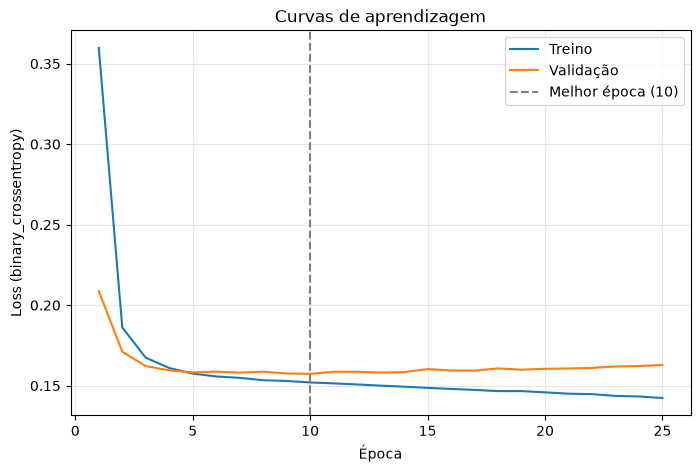

Total de épocas treinadas: 25
Melhor época: 10
val_loss na melhor época: 0.1574
loss (treino) na melhor época: 0.1520


In [61]:
import matplotlib.pyplot as plt

hist = history.history
epocas = range(1, len(hist["loss"]) + 1)

# Melhor época: a de menor val_loss (é de onde o EarlyStopping restaurou os pesos)
melhor_epoca = int(np.argmin(hist["val_loss"])) + 1

plt.figure(figsize=(8, 5))
plt.plot(epocas, hist["loss"], label="Treino")
plt.plot(epocas, hist["val_loss"], label="Validação")
plt.axvline(melhor_epoca, color="gray", linestyle="--",
            label=f"Melhor época ({melhor_epoca})")
plt.xlabel("Época")
plt.ylabel("Loss (binary_crossentropy)")
plt.title("Curvas de aprendizagem")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Total de épocas treinadas: {len(epocas)}")
print(f"Melhor época: {melhor_epoca}")
print(f"val_loss na melhor época: {hist['val_loss'][melhor_epoca-1]:.4f}")
print(f"loss (treino) na melhor época: {hist['loss'][melhor_epoca-1]:.4f}")

In [62]:
resultados = model.evaluate(X_test_p, y_test, verbose=0)
for nome, valor in zip(model.metrics_names, resultados):
    print(f"{nome}: {valor:.4f}")

loss: 0.1683
compile_metrics: 0.9505


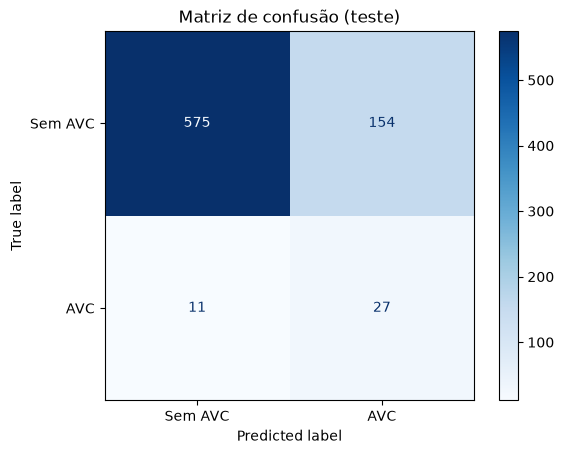

VP=27  FN=11  FP=154  VN=575


In [70]:
y_prob = model.predict(X_test_p, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Sem AVC", "AVC"]).plot(cmap="Blues")
plt.title("Matriz de confusão (teste)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"VP={tp}  FN={fn}  FP={fp}  VN={tn}")

Aluno: Gabriel Expedito Siqueira Silva